<a href="https://colab.research.google.com/github/Ayaaba-Fatawu-Sumaila/Machine-Learning-Journey/blob/main/BankCustomerChurn_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Importing the neccessary libraries

In [1]:
#Exploratory Data Analysis(EDA)
import pandas as pd
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import zscore

#Splitting data into training and testing
from sklearn.model_selection import train_test_split

#Scaling data to prevent overfitting
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder

#Pipeline for data transformation and model training
from sklearn.pipeline import make_pipeline, Pipeline

#Models for training
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier,AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import VotingClassifier
from tensorflow.keras import Sequential
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

#Evaluating the individual models
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.model_selection import cross_val_score

#Hyperparameter tuning for best parameters
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

#Model Evaluation metrics
from sklearn.metrics import confusion_matrix,classification_report

#ignore warning
import warnings
warnings.filterwarnings('ignore')

In [2]:
#Reading the .csv files into a dataframe
train_data = pd.read_csv("train_preprocessed.csv")
test_data = pd.read_csv("test_preprocessed.csv")

In [3]:
print(f"The rows of the training set are {train_data.shape[0]} and testing set is {test_data.shape[0]}")

The rows of the training set are 165034 and testing set is 110023


### EXPLORATORY DATA ANALYSIS

In [4]:
test_data.isnull().sum() #sum of null values per column

,0
id,0
CustomerId,0
Surname,0
CreditScore,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0
HasCrCard,0
IsActiveMember,0


In [5]:
train_data.nunique() #Number of unique values of the individual columns

,0
id,165034
CustomerId,23221
Surname,2797
CreditScore,457
Age,71
Tenure,11
Balance,30075
NumOfProducts,4
HasCrCard,2
IsActiveMember,2


In [6]:
train_data.head() #First 5 rows of the data

,id,CustomerId,Surname,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,AgeCategory,CreditScoreCategory,BalanceCategory,SalaryCategory,Geography_Germany,Geography_Spain,Gender_Male
0,0,15674932,Okwudilichukwu,668,33.0,3,0.00,2,1.0,0.0,181449.97,0,2,1.0,3.0,5.0,0.0,0.0,1.0
1,1,15749177,Okwudiliolisa,627,33.0,1,0.00,2,1.0,1.0,49503.50,0,2,1.0,3.0,1.0,0.0,0.0,1.0
2,2,15694510,Hsueh,678,40.0,10,0.00,2,1.0,0.0,184866.69,0,3,2.0,3.0,5.0,0.0,0.0,1.0
3,3,15741417,Kao,581,34.0,2,148882.54,1,1.0,1.0,84560.88,0,2,1.0,1.0,2.0,0.0,0.0,1.0
4,4,15766172,Chiemenam,716,33.0,5,0.00,2,1.0,1.0,15068.83,0,2,2.0,3.0,6.0,0.0,1.0,1.0


In [7]:
train_data.info() #General information of the data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165034 entries, 0 to 165033
Data columns (total 19 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   id                   165034 non-null  int64  
 1   CustomerId           165034 non-null  int64  
 2   Surname              165034 non-null  object 
 3   CreditScore          165034 non-null  int64  
 4   Age                  165034 non-null  float64
 5   Tenure               165034 non-null  int64  
 6   Balance              165034 non-null  float64
 7   NumOfProducts        165034 non-null  int64  
 8   HasCrCard            165034 non-null  float64
 9   IsActiveMember       165034 non-null  float64
 10  EstimatedSalary      165034 non-null  float64
 11  Exited               165034 non-null  int64  
 12  AgeCategory          165034 non-null  int64  
 13  CreditScoreCategory  165034 non-null  float64
 14  BalanceCategory      165034 non-null  float64
 15  SalaryCategory   

In [8]:
train_data.duplicated().sum() #The total number of repeated rows

np.int64(0)

In [9]:
train_data.columns #Checking for inconsistent column names

Index(['id', 'CustomerId', 'Surname', 'CreditScore', 'Age', 'Tenure',
       'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember',
       'EstimatedSalary', 'Exited', 'AgeCategory', 'CreditScoreCategory',
       'BalanceCategory', 'SalaryCategory', 'Geography_Germany',
       'Geography_Spain', 'Gender_Male'],
      dtype='object')

In [10]:
names = train_data.select_dtypes(include="object").columns #Categorical column
names

Index(['Surname'], dtype='object')

In [11]:
train_data.Surname.str.lower().unique() #Checking for unique surenames of customers

array(['okwudilichukwu', 'okwudiliolisa', 'hsueh', ..., 'aliyev',
       'mcminn', 'elkins'], dtype=object)

In [12]:
train_data.describe(include=np.number) #Statistical summary of the data

,id,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,AgeCategory,CreditScoreCategory,BalanceCategory,SalaryCategory,Geography_Germany,Geography_Spain,Gender_Male
count,165034.0000,1.650340e+05,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000
mean,82516.5000,1.569201e+07,656.454373,38.125888,5.020353,55478.086689,1.554455,0.753954,0.497770,112574.822734,0.211599,2.666796,1.980537,1.999836,2.597265,0.209690,0.219428,0.564429
std,47641.3565,7.139782e+04,80.103340,8.867205,2.806159,62817.663278,0.547154,0.430707,0.499997,50292.865585,0.408443,0.639941,1.144807,1.123100,1.843329,0.407089,0.413860,0.495833
min,0.0000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,11.580000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,41258.2500,1.563314e+07,597.000000,32.000000,3.000000,0.000000,1.000000,1.000000,0.000000,74637.570000,0.000000,2.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
50%,82516.5000,1.569017e+07,659.000000,37.000000,5.000000,0.000000,2.000000,1.000000,0.000000,117948.000000,0.000000,3.000000,2.000000,3.000000,3.000000,0.000000,0.000000,1.000000
75%,123774.7500,1.575682e+07,710.000000,42.000000,7.000000,119939.517500,2.000000,1.000000,1.000000,155152.467500,0.000000,3.000000,3.000000,3.000000,4.000000,0.000000,0.000000,1.000000
max,165033.0000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.000000,1.000000,199992.480000,1.000000,4.000000,4.000000,3.000000,6.000000,1.000000,1.000000,1.000000


In [13]:
#Wrangling function
def wrangle(data_path):
    df = (pd.read_csv(data_path)
          .drop("id",axis=1)) #Reading the data and dropping the 'id' column

    #Dropping duplicate
    df=df.drop_duplicates()

    #Filling missing values
    df=df.interpolate()

    #Dropping outliers to improve model performance and generalisation
    mask1 = (df["CreditScore"] >= 400) #Dropping values of credit score below 400

    mask2 = (df["Age"] < 90) #Dropping ages from 90+

    df = df[mask1 & mask2]
    return df

In [14]:
train_df = wrangle("train_preprocessed.csv") #Calling the function to clean up the data

#### Outliers Detection


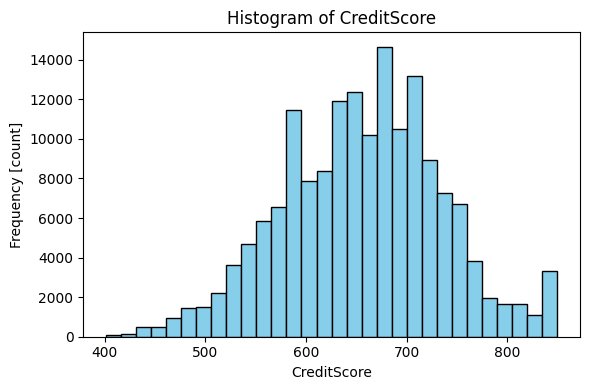

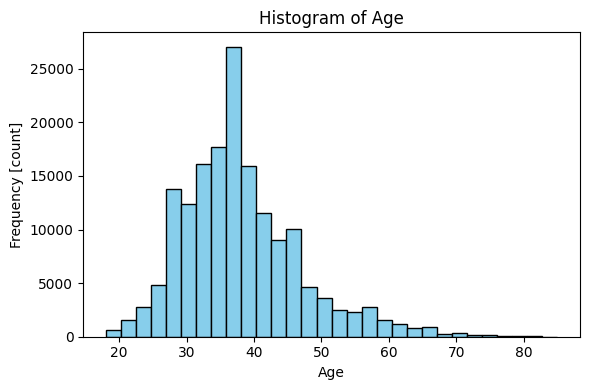

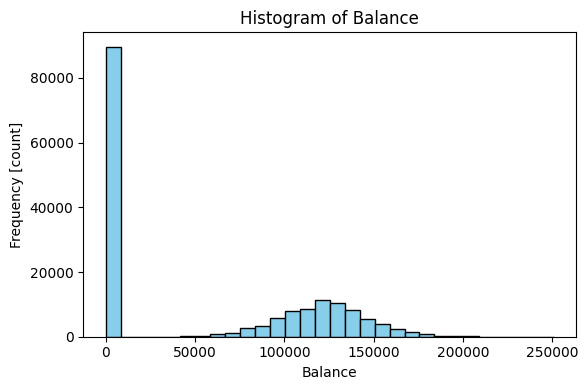

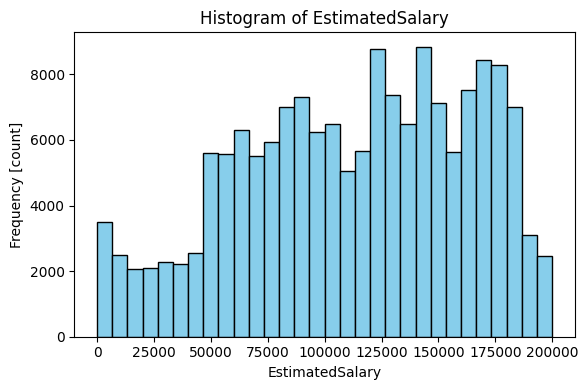

In [15]:
#Histogram
cols = ["CreditScore","Age","Balance","EstimatedSalary"]

for col in cols:
    plt.figure(figsize=(6, 4))
    plt.hist(train_df[col], bins=30, color='skyblue', edgecolor='black')
    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency [count]")
    plt.tight_layout()
    plt.show()

In [16]:
#The above "CreditScore" and "Balance" histogram shows possible outliers. Since Balance can be '0' it has a lot of data, there is no need dropping it
#Plot a boxplot

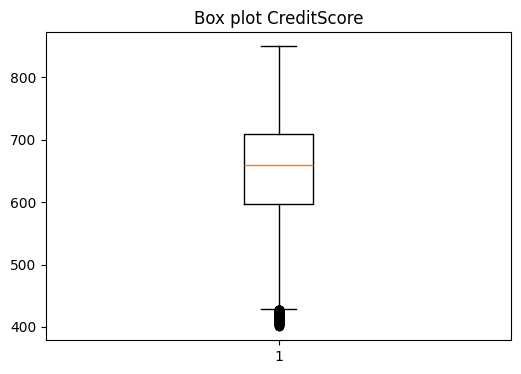

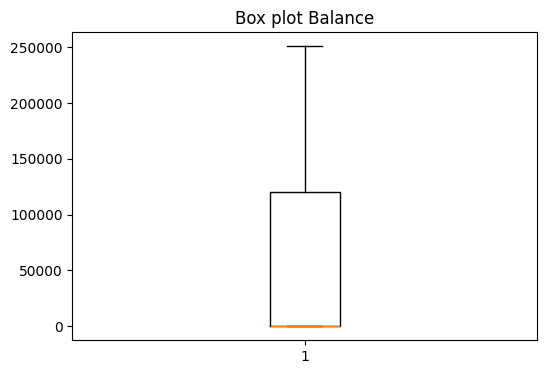

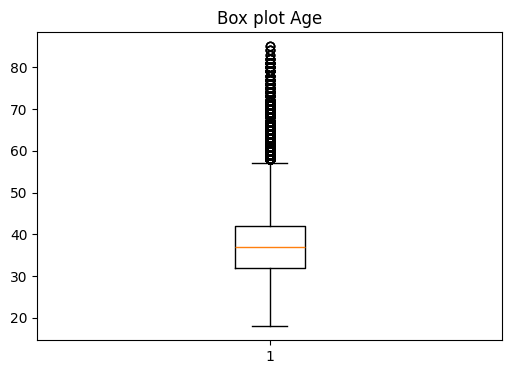

In [17]:
out_col = ["CreditScore","Balance","Age"]
for col in out_col:
    plt.figure(figsize=(6,4))
    plt.boxplot(train_df[col])
    plt.title(f"Box plot {col}");

### Data Visualisation and Analysis

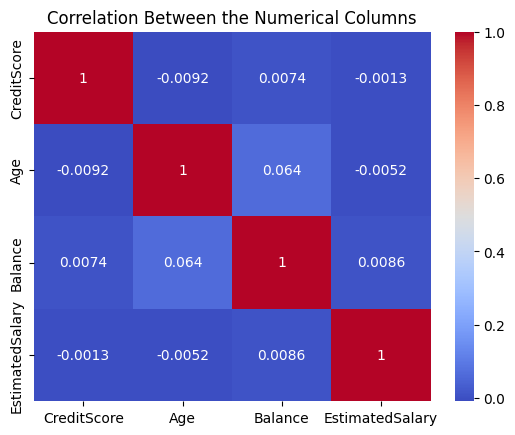

In [18]:
#The correlation between the numerical columns
corr = train_df[cols].corr()
sns.heatmap(corr,annot=True,cmap="coolwarm")
plt.title("Correlation Between the Numerical Columns")
plt.savefig("bank-cutomer-churn-correlation.png")
plt.show()

The heatmap shows a weak positive and negative correlation between numerical variables of the dataset

In [19]:
#Percentage of churn and not churn customers
churn_customers_percent = train_df["Exited"].value_counts(normalize=True)
fig = px.bar(data_frame=churn_customers_percent ,
             y = churn_customers_percent.values,
             x= churn_customers_percent.index,
             color=['Retained','Churn']



            )
fig.update_layout(yaxis_title="Percentgae[%]",xaxis_title="Churn",title="Percentage of Churn and Retained Customers")
fig.show()

The above bar plot shows that, about 21% of the customers have churn

In [20]:
#Age Category that are likely to churn as well as the age category the constribute the highest customers
churn_age = pd.crosstab(index=train_df["AgeCategory"],columns=train_df["Exited"],normalize=True)

fig = px.bar(data_frame=churn_age,
             opacity=0.8
            )
fig.update_layout(xaxis_title="Age Category",
                  yaxis_title="Total Customers[%]",
                  title="The percentage of Churn and Retained Customers per Age Category")
fig.show()

The age category 2 has most of the customers with over 38% of retained customers and approximately 3.7% churn customers
 However the age category 3 is the second higher percentage of customers with a percentage of 36% retained and 12.7 churn
 With a less customers from the age categories 3 and 1 respectively, with a 4.9% churn age the age of 4 more than 4.3% retained

In [21]:
#Age Category that are likely to churn as well as the age category the constribute the highest customers
churn_gender = pd.crosstab(index=train_df["Gender_Male"],columns=train_df["Exited"],normalize=True)

fig = px.bar(data_frame=churn_gender,
             opacity=0.9
            )
fig.update_layout(xaxis_title="Gender Male",
                  yaxis_title="Total Customers[%]",
                  title="The percentage of Churn and Retained Customers per Customer Gender")
fig.show()

Most of the customers consist of males of about 47.5% retained and approximately 9% churn

The females constribute to 31.4% of retained and 12% churn

In [22]:
#Top 10 customers by percentage
top_customers = train_df.Surname.value_counts(normalize=True).sort_values(ascending=False).head(10)
fig = px.bar(data_frame=top_customers,
             y=top_customers.values,
             x=top_customers.index
            )
fig.update_layout(xaxis_title="Customer Surname",
                  yaxis_title="Percentage of Contribution",
                  title="Percentage of top 10 customers")
fig.show()

In [23]:
#Top 10 higher number of products by customers Surname
top_customers_prod = train_df.groupby("Surname")["NumOfProducts"].sum().sort_values(ascending=False).head(10)
fig = px.bar(data_frame=top_customers_prod,
             y=top_customers_prod.values,
             x=top_customers_prod.index
            )
fig.update_layout(xaxis_title="Customer Surname",
                  yaxis_title="Total Number of Products",
                  title="Number of Products of top 10 customers")
fig.show()

Maintaing these top customers will improve success

In [24]:
#Checking for the relationship between active, none active members to Exited
churn_state = pd.crosstab(index=train_df["IsActiveMember"],columns=train_df["Exited"],normalize=True)

fig = px.bar(data_frame=churn_state,
             opacity=0.9
            )
fig.update_layout(xaxis_title="Active and Non Active Members",
                  yaxis_title="Total Customers[count]",
                  title="The percentage of Churn and Retained Customers per Active State")
fig.show()

Most of the inactive members about 15% have churn while 6% of the active members have churn

43.5% of active members retained while 35.3% of inactive members have retained

### Model Building

Training different classification supervised machine learning models for customer churn detection.

In [25]:
#Setting a baseline

In [26]:
baseline = train_df.Exited.value_counts(normalize=True)

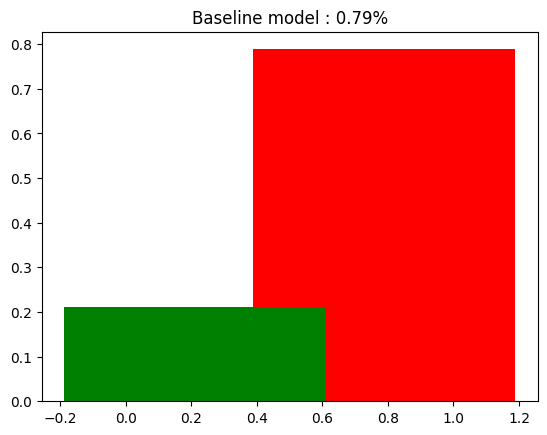

In [27]:
plt.bar(baseline, height=baseline.values,color=["red","green"],)
plt.title(f"Baseline model : {round(baseline.max(),2)}%");

### Scaling the numberical columns

In [28]:
#Creating a function to handle the scaling of the numerical columns
def scale(data,num_cols):
    #Running a for loop to scale the individual column values  0 <= 1
    for cols in num_cols:
        data[cols] = train_df[cols]/train_df[cols].max()
    return data

In [29]:
#Taking inputs of the dataframe and the columns to be scaled
train_df = scale(train_df,['CreditScore','Age','NumOfProducts','Balance','EstimatedSalary','CustomerId'])

In [30]:
train_df.head()

,CustomerId,Surname,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,AgeCategory,CreditScoreCategory,BalanceCategory,SalaryCategory,Geography_Germany,Geography_Spain,Gender_Male
0,0.991100,Okwudilichukwu,0.785882,0.388235,3,0.000000,0.50,1.0,0.0,0.907284,0,2,1.0,3.0,5.0,0.0,0.0,1.0
1,0.995794,Okwudiliolisa,0.737647,0.388235,1,0.000000,0.50,1.0,1.0,0.247527,0,2,1.0,3.0,1.0,0.0,0.0,1.0
2,0.992338,Hsueh,0.797647,0.470588,10,0.000000,0.50,1.0,0.0,0.924368,0,3,2.0,3.0,5.0,0.0,0.0,1.0
3,0.995304,Kao,0.683529,0.400000,2,0.593398,0.25,1.0,1.0,0.422820,0,2,1.0,1.0,2.0,0.0,0.0,1.0
4,0.996869,Chiemenam,0.842353,0.388235,5,0.000000,0.50,1.0,1.0,0.075347,0,2,2.0,3.0,6.0,0.0,1.0,1.0


In [31]:
### Splitting the data into feature and target variables

In [32]:
X = train_df.drop(["Exited","Surname"],axis=1)
y = train_df.Exited

In [33]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)

In [34]:
print(f"X_train shape = {X_train.shape}")
print(f"X_test shape = {X_test.shape}")
print(f"y_train shape = {y_train.shape}")
print(f"y_test shape = {y_test.shape}")

X_train shape = (131973, 16)
X_test shape = (32994, 16)
y_train shape = (131973,)
y_test shape = (32994,)


### Training model using ANN

In [35]:
#Building a neural network model
model = Sequential([
    layers.Dense(64,input_shape=[X_train.shape[1]],activation="sigmoid"), #Taking inputs of units, feature shape, setting activation energy to sigmoid
    layers.BatchNormalization(), #Normalising and scaling the data
    layers.Dropout(0.5), #Preventing overfitting of the data
    layers.Dense(32,activation="relu"), #Hidding layer with 32 units and using a ReLu activation energy
    layers.BatchNormalization(), #Normalising and scaling the data
    layers.Dropout(0.5), #Preventing overfitting of the data
    layers.Dense(16,activation="relu"), #Hidding layer with 16 units and using a ReLu activation energy
    layers.BatchNormalization(), #Normalising and scaling the data
    layers.Dropout(0.5), #Preventing overfitting of the data
    layers.Dense(8,activation="relu"), #Hidding layer with 8 units and using a ReLu activation energy
    layers.BatchNormalization(), #Normalising and scaling the data
    layers.Dropout(0.5), #Preventing overfitting of the data
    layers.Dense(1,activation="sigmoid") #Hidding layer with 1 unit output and using a sigmoid activation energy
])

In [36]:
#Compiling the neural model
model.compile(
    optimizer="adam", #Setting the optimizer to Adam
    loss="categorical_crossentropy", #Using categorical crossentropy loss , since it's classification
    metrics=["accuracy"] #Using a an 'accuracy metrics'
)

In [37]:
#Early stopping , to stop the model when there's no more improvement
early_stop = EarlyStopping(
        patience=10,
        min_delta=1

)

In [38]:
#Fitting the model
history = model.fit(X_train,y=y_train,validation_data=(X_test,y_test) ,epochs=20, batch_size=32,callbacks=[early_stop])

Epoch 1/20
4125/4125 ━━━━━━━━━━━━━━━━━━━━ 18s 3ms/step - accuracy: 0.7462 - loss: 0.0000e+00 - val_accuracy: 0.8418 - val_loss: 0.0000e+00
Epoch 2/20
4125/4125 ━━━━━━━━━━━━━━━━━━━━ 18s 3ms/step - accuracy: 0.8253 - loss: 0.0000e+00 - val_accuracy: 0.8373 - val_loss: 0.0000e+00
Epoch 3/20
4125/4125 ━━━━━━━━━━━━━━━━━━━━ 20s 2ms/step - accuracy: 0.8271 - loss: 0.0000e+00 - val_accuracy: 0.8444 - val_loss: 0.0000e+00
Epoch 4/20
4125/4125 ━━━━━━━━━━━━━━━━━━━━ 22s 3ms/step - accuracy: 0.8296 - loss: 0.0000e+00 - val_accuracy: 0.8540 - val_loss: 0.0000e+00
Epoch 5/20
4125/4125 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.8343 - loss: 0.0000e+00 - val_accuracy: 0.8568 - val_loss: 0.0000e+00
Epoch 6/20
4125/4125 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8369 - loss: 0.0000e+00 - val_accuracy: 0.8570 - val_loss: 0.0000e+00
Epoch 7/20
4125/4125 ━━━━━━━━━━━━━━━━━━━━ 21s 3ms/step - accuracy: 0.8405 - loss: 0.0000e+00 - val_accuracy: 0.8578 - val_loss: 0.0000e+00
Epoch 8/20
4125/4125 ━━━━━━

In [39]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8)              │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,485 (48.77 KB)

 Trainable params: 4,081 (15.94 KB)

 Non-trainable params: 240 (960.00 B)

 Optimizer params: 8,164 (31.89 KB)

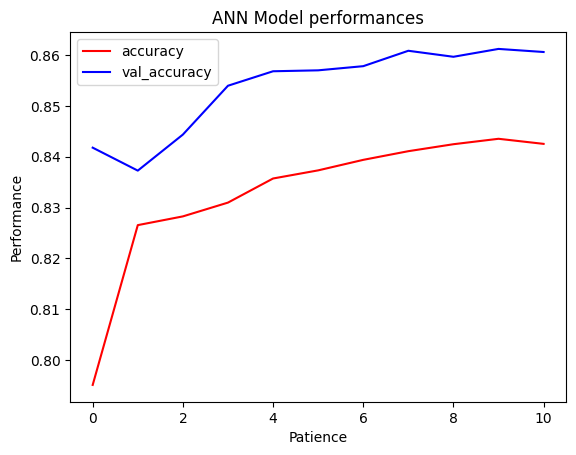

In [40]:
plt.plot(history.history['accuracy'],color='r',label="accuracy")
plt.plot(history.history['val_accuracy'],color='b',label="val_accuracy")
plt.ylabel("Performance")
plt.yscale("linear")
plt.xlabel("Patience")
plt.title("ANN Model performances")
plt.legend();

In [41]:
### ML models training

In [42]:
#A Json containing a nested model name and parameters for hyperparameter tuning
model = {
    "randomforest":{
        "models": RandomForestClassifier(),
        "params":{
            "n_estimators":[50,100,150,200],
            "random_state":np.arange(20,100,10)
        }
    },
    "XGBClassifier":{
        "models": XGBClassifier(),
        "params":{
            "n_estimators":[50,100,150,200],
            "learning_rate":[0.05,0.1,0.15,0.2,0.3,0.4,0.5],
            "booster":['gbtree', 'gblinear' ,'dart']
        }
    },
    "GradientBoosting":{
        "models": GradientBoostingClassifier(),
        "params":{
            "n_estimators":[50,100,150,200],
            "random_state":np.arange(20,100,10),
            "learning_rate":[0.05,0.1,0.15,0.2,0.3,0.4,0.5],
            "loss" : ['log_loss', 'exponential']
        }
    },
    "AdaBoosting":{
        "models": AdaBoostClassifier(),
        "params":{
            "n_estimators":[50,100,150,200],
            "random_state":np.arange(20,100,10),
            "learning_rate":[0.05,0.1,0.15,0.2,0.3,0.4,0.5]
        }
    },
    "GaussianNB":{
        "models": GaussianNB(),
        "params":{
            "var_smoothing":[1e-06,1e-09,1e-012]

        }
    },
    "MultinomialNB":{
        "models": MultinomialNB(),
        "params":{
            "alpha":[1.0,0.05,0.0],
            "force_alpha":[True,False],
            "fit_prior":[True,False]
        }
    },
    "KNeighborsClassifier":{
        "models": KNeighborsClassifier(),
        "params":{
            "n_neighbors":np.arange(2,16,2),
            "weights" : ['uniform', 'distance'],
            "algorithm" : ['auto', 'ball_tree', 'kd_tree', 'brute']

        }
    },
    "DecisionTree":{
        "models": DecisionTreeClassifier(),
        "params":{
            "criterion" : ["gini", "entropy", "log_loss"],
            "splitter" : ["best", "random"],
            "random_state":np.arange(20,100,10)

        }
    }

}

Model name : randomforest

Best Score : 0.8601077500679913
Best Parameters: {'random_state': np.int64(60), 'n_estimators': 200}
Classification report :               precision    recall  f1-score   support

           0       0.89      0.95      0.92     26162
           1       0.72      0.55      0.62      6832

    accuracy                           0.86     32994
   macro avg       0.81      0.75      0.77     32994
weighted avg       0.86      0.86      0.86     32994

Model name : XGBClassifier

Best Score : 0.8652527505756208
Best Parameters: {'n_estimators': 150, 'learning_rate': 0.1, 'booster': 'dart'}
Classification report :               precision    recall  f1-score   support

           0       0.89      0.95      0.92     26162
           1       0.73      0.56      0.64      6832

    accuracy                           0.87     32994
   macro avg       0.81      0.75      0.78     32994
weighted avg       0.86      0.87      0.86     32994

Model name : GradientBoosting


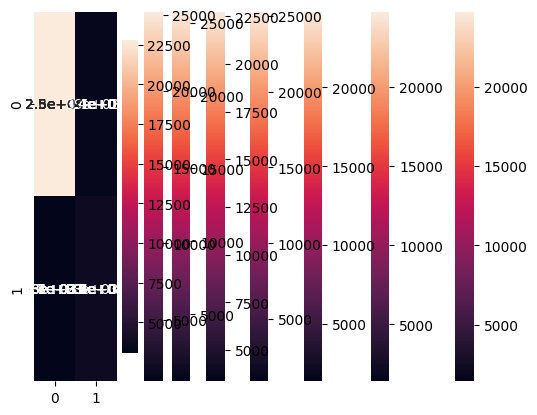

In [43]:
#Running a for loop through the json to access the items, model names and parameters for training
for name,mod in model.items():
    clf = RandomizedSearchCV(mod["models"],mod["params"],cv=5) #hyperparameter tuning
    clf.fit(X_train,y_train) #Training the model using the training datasets
    print(f"Model name : {name}\n") #Model name
    print(f"Best Score : {clf.best_score_}") # Best score per model
    print(f"Best Parameters: {clf.best_params_}") # Identified best parameters
    sns.heatmap(confusion_matrix(y_test,clf.predict(X_test)),annot=True)
    print(f"Classification report : {classification_report(y_test,clf.predict(X_test))}")



In [44]:
#Since the best performing models are RandomForestClassifier,GradientBoostingClassifier,AdaBoostClassifier
#Using a voting classifier by using them as estimators will boost model performance

In [45]:
voting = VotingClassifier(estimators=[
    ("randomforest",RandomForestClassifier(random_state= np.int64(90), n_estimators= 100)),
    ("gradientboosting",GradientBoostingClassifier(random_state= np.int64(40), n_estimators= 200, loss= 'exponential', learning_rate= 0.2)),
    ("adaboosting",AdaBoostClassifier(random_state= np.int64(60), n_estimators= 150, learning_rate= 0.5))

    ]
)

In [46]:
# Creating a pipeline for the model
model_pipeline = make_pipeline(MinMaxScaler(),voting)

In [47]:
#Untrained model pipeline
model_pipeline

Pipeline(steps=[('minmaxscaler', MinMaxScaler()),
                ('votingclassifier',
                 VotingClassifier(estimators=[('randomforest',
                                               RandomForestClassifier(random_state=np.int64(90))),
                                              ('gradientboosting',
                                               GradientBoostingClassifier(learning_rate=0.2,
                                                                          loss='exponential',
                                                                          n_estimators=200,
                                                                          random_state=np.int64(40))),
                                              ('adaboosting',
                                               AdaBoostClassifier(learning_rate=0.5,
                                                                  n_estimators=150,
                                                                  random_state=np.int64(60)))]))])

In [48]:
#Training the model
model_pipeline.fit(X_train,y_train)

Pipeline(steps=[('minmaxscaler', MinMaxScaler()),
                ('votingclassifier',
                 VotingClassifier(estimators=[('randomforest',
                                               RandomForestClassifier(random_state=np.int64(90))),
                                              ('gradientboosting',
                                               GradientBoostingClassifier(learning_rate=0.2,
                                                                          loss='exponential',
                                                                          n_estimators=200,
                                                                          random_state=np.int64(40))),
                                              ('adaboosting',
                                               AdaBoostClassifier(learning_rate=0.5,
                                                                  n_estimators=150,
                                                                  random_state=np.int64(60)))]))])

In [49]:
model_pipeline.score(X_test,y_test)

0.866672728374856

In [ ]:
features = model_pipeline.feature_names_in_

### Saving the model Using pickle

In [ ]:
import pickle as pkl

In [ ]:
with open("customer_churn_model","wb") as file:
    pkl.dump(model_pipeline,file)